# 01 — Análise exploratória (CirCor DigiScope, parte pública)

**Objetivo do projeto:** prever, **por paciente**, o rótulo `Murmur` (*Present / Unknown / Absent*) a partir dos fonocardiogramas (PCG),
avaliado com a *weighted accuracy* do PhysioNet Challenge 2022 (Present ×5, Unknown ×3, Absent ×1).

Diferença face ao projeto UrbanSound8K (`example/`): lá cada clip de ≤4 s tinha **uma** classe (a fonte do som).
Aqui o rótulo é do **paciente**, que tem várias gravações longas (uma por foco de auscultação), e o sopro pode ouvir-se só nalguns focos.
Por isso esta análise responde a quatro perguntas que determinam o pré-processamento:

1. Como estão distribuídos os rótulos e que *baseline* temos? (§1–2)
2. Como é um sopro: onde, quando no ciclo cardíaco, que frequências? (§3, §6–7)
3. Que forma têm as gravações: duração, focos, qualidade, *sample rate*? (§4–5, §8)
4. Que consequências tem tudo isto para o pré-processamento? (§9 → implementado em `02_preprocessing.ipynb`)

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa, librosa.display, scipy.signal as ss
from tqdm.auto import tqdm
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

from src.data import (load_patients, load_recordings, load_split, load_segmentation,
                      segmentation_stats, DATA_DIR, WAV_DIR, CLASSES)
from src.metrics import weighted_accuracy
from src import features as F

pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Present': '#d62728', 'Unknown': '#7f7f7f', 'Absent': '#1f77b4'}
FIG_DIR = Path('../results/eda'); FIG_DIR.mkdir(parents=True, exist_ok=True)
save = lambda name: plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
print('dataset em', DATA_DIR)

dataset em C:\Users\rafa\Documents\FCUP\AC 2\FCUP-DL-ML2\data\the-circor-digiscope-phonocardiogram-dataset-1.0.3


c:\Users\rafa\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Pacientes e rótulos

942 pacientes


,count,pct
Murmur,,
Present,179,19.0
Unknown,68,7.2
Absent,695,73.8


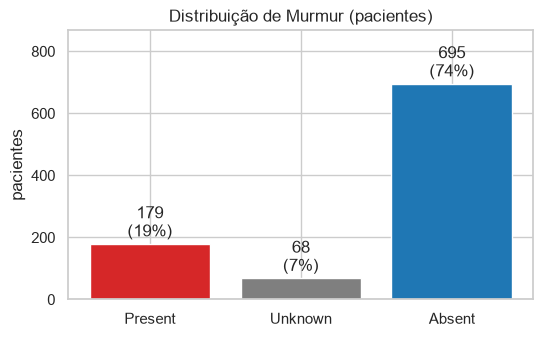

In [2]:
pat = load_patients()
print(len(pat), 'pacientes')
counts = pat['Murmur'].value_counts().reindex(CLASSES)
display(counts.to_frame().assign(pct=lambda d: (100 * d['count'] / d['count'].sum()).round(1)))

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
ax.bar_label(bars, labels=[f'{v}\n({100*v/counts.sum():.0f}%)' for v in counts.values], padding=2)
ax.set(title='Distribuição de Murmur (pacientes)', ylabel='pacientes', ylim=(0, counts.max() * 1.25))
save('class_distribution'); plt.show()

In [3]:
# Baselines triviais com a métrica oficial
for c in CLASSES:
    print(f'sempre {c:8s} WA = {weighted_accuracy(pat.Murmur, [c] * len(pat)):.3f}')

sempre Present  WA = 0.499
sempre Unknown  WA = 0.114
sempre Absent   WA = 0.387


**Leitura.** O desequilíbrio é forte (≈74 % *Absent*, 7 % *Unknown*). Com a *weighted accuracy* a lógica inverte-se:
prever sempre *Absent* dá só ≈0.39, prever sempre *Present* dá ≈0.50. Este é o valor mínimo que um modelo tem de bater.
Na prática, falhar um *Present* custa 5× mais do que um falso alarme, o que justifica pesos de classe na loss
e um limiar de decisão afinado na validação.

## 2. Demografia, campanhas e pacientes repetidos

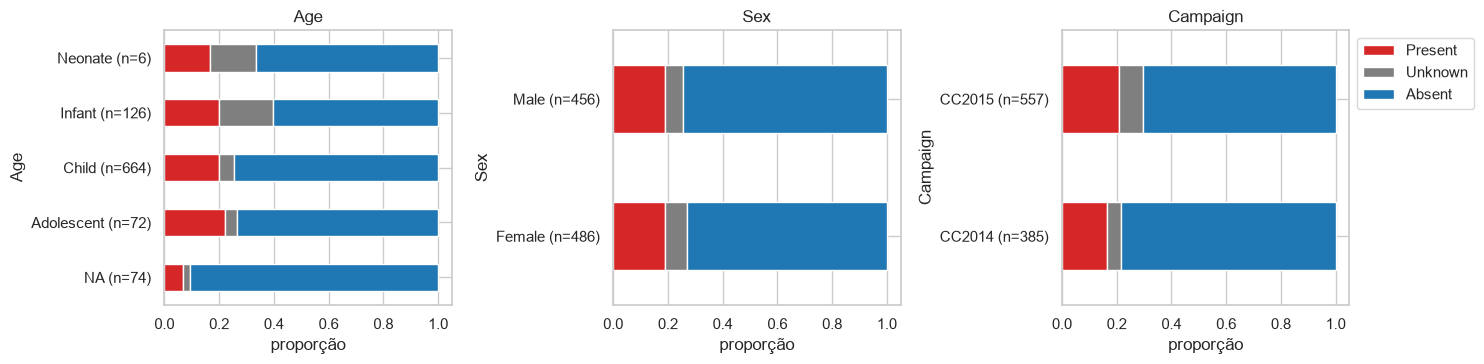

Grávidas: 70 | idade em falta: 74


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ['Age', 'Sex', 'Campaign']):
    ct = pd.crosstab(pat[col].fillna('NA'), pat['Murmur'], normalize='index')[CLASSES]
    if col == 'Age': ct = ct.reindex(['NA', 'Adolescent', 'Child', 'Infant', 'Neonate'])
    ct.plot.barh(stacked=True, color=[PALETTE[c] for c in CLASSES], ax=ax, legend=ax is axes[-1])
    n = pat[col].fillna('NA').value_counts()
    ax.set_yticklabels([f'{t.get_text()} (n={n[t.get_text()]})' for t in ax.get_yticklabels()])
    ax.set(title=col, xlabel='proporção')
axes[-1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); save('demographics_vs_murmur'); plt.show()

print('Grávidas:', pat['Pregnancy status'].sum(), '| idade em falta:', pat.Age.isna().sum())

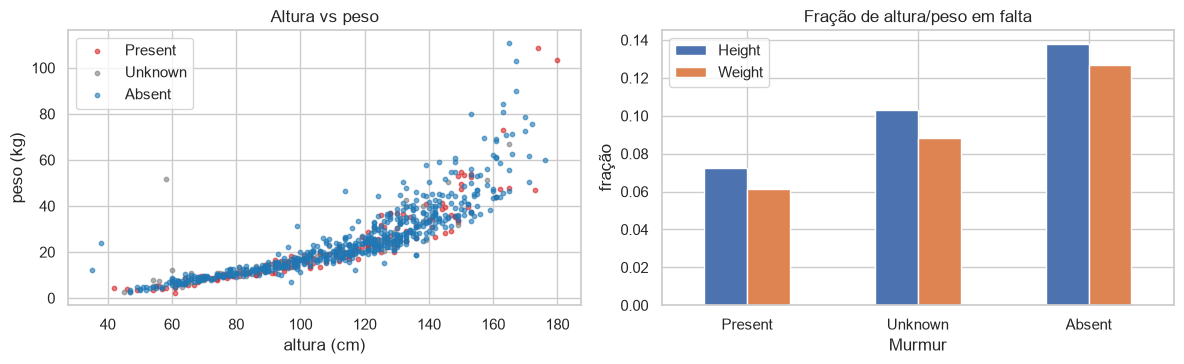

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for c in CLASSES:
    sub = pat[pat.Murmur == c]
    ax[0].scatter(sub.Height, sub.Weight, s=10, alpha=.6, color=PALETTE[c], label=c)
ax[0].set(xlabel='altura (cm)', ylabel='peso (kg)', title='Altura vs peso'); ax[0].legend()
pat[['Height', 'Weight']].isna().groupby(pat.Murmur).mean().reindex(CLASSES).plot.bar(ax=ax[1], rot=0)
ax[1].set(title='Fração de altura/peso em falta', ylabel='fração')
plt.tight_layout(); plt.show()

In [6]:
# Additional ID: a mesma criança vista nas duas campanhas -> mesmo grupo no split (src/make_split.py)
rep = pat[pat['Additional ID'].notna()]
print(len(rep), 'pacientes com Additional ID')
pairs = rep.reset_index()[['Patient ID', 'Additional ID', 'Murmur']]
pairs['Murmur (outra campanha)'] = pairs['Additional ID'].astype(int).map(pat.Murmur)
pd.crosstab(pairs['Murmur'], pairs['Murmur (outra campanha)'].fillna('não está na parte pública'))

140 pacientes com Additional ID


Murmur (outra campanha),Absent,Present,Unknown
Murmur,,,
Absent,72,4,6
Present,4,36,5
Unknown,6,5,2


**Leitura.**
- Os *Infant* têm muito mais *Unknown* (crianças pequenas mexem-se e choram, por isso há mais ruído).
  A faixa etária explica parte do *Unknown*, mas não usamos a demografia como entrada: o enunciado foca o áudio
  e a idade falta em ~8 % dos pacientes. Fica como possível extensão.
- A campanha CC2015 tem mais *Present* e *Unknown* do que a CC2014. O split estratificado mantém a proporção global de classes,
  mas convém ver se os erros se concentram numa campanha.
- Os 140 pacientes com `Additional ID` são 70 crianças vistas nas duas campanhas. Ficam no mesmo fold (já é assim no `split.csv`, verificado em `02_preprocessing.ipynb`).
  A tabela mostra que o rótulo **nem sempre coincide** entre as duas visitas (cada par aparece duas vezes, uma em cada linha).
  O próprio rótulo tem ruído, sobretudo à volta de *Unknown*, e isto limita a *accuracy* atingível.

## 3. Como é um sopro? (pacientes *Present*)
O CSV descreve cada sopro: em que fase do ciclo aparece, a forma, a intensidade (*grading*), o tom e a qualidade.
Isto diz-nos que padrão tempo-frequência os modelos têm de encontrar.

sopro sistólico: 178 | diastólico: 5 | ambos: 4 de 179


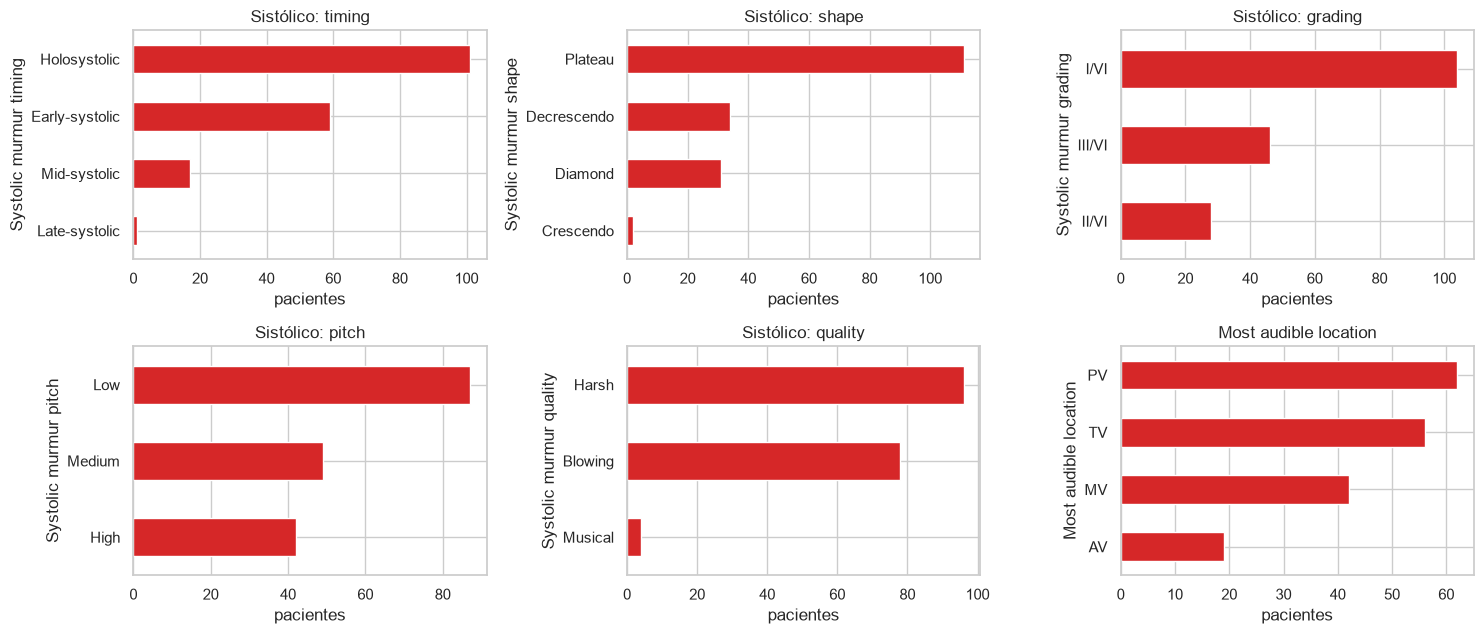

In [7]:
present = pat[pat.Murmur == 'Present']
print('sopro sistólico:', present['Systolic murmur timing'].notna().sum(),
      '| diastólico:', present['Diastolic murmur timing'].notna().sum(),
      '| ambos:', (present['Systolic murmur timing'].notna() & present['Diastolic murmur timing'].notna()).sum(),
      'de', len(present))

cols = ['Systolic murmur timing', 'Systolic murmur shape', 'Systolic murmur grading',
        'Systolic murmur pitch', 'Systolic murmur quality', 'Most audible location']
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, col in zip(axes.flat, cols):
    present[col].value_counts().plot.barh(ax=ax, color='#d62728')
    ax.set(title=col.replace('Systolic murmur ', 'Sistólico: '), xlabel='pacientes'); ax.invert_yaxis()
plt.tight_layout(); save('murmur_characteristics'); plt.show()

**Leitura.**
- Os sopros são quase todos **sistólicos** (entre S1 e S2). Os diastólicos são raríssimos.
- Predominam *holosystolic* (toda a sístole) e *early-systolic*, de forma *plateau* (intensidade constante),
  maioritariamente de grau I/VI (**muito fracos**) e de tom *low*, com qualidade *harsh* ou *blowing*.
  Um sopro típico é um ruído fraco e de banda larga que enche o intervalo entre S1 e S2.
- O foco onde se ouve melhor é sobretudo PV ou TV. AV é o menos frequente.
- Consequência para o modelo: a janela de entrada tem de conter **ciclos cardíacos completos**, para se ver o que se passa entre S1 e S2.
  Por isso usamos janelas de 4 s em vez de frames curtos (`02_preprocessing.ipynb`). E a resolução temporal tem de ser fina (10 ms) para separar S1/sístole/S2.

## 4. Gravações: número, focos, duração

In [8]:
rec = load_recordings()
info = [sf.info(p) for p in tqdm(rec.path, desc='headers')]
rec['sr'] = [i.samplerate for i in info]
rec['duration'] = [i.duration for i in info]
rec['fold'] = rec.patient_id.map(load_split().fold)
print(len(rec), 'gravações;', rec.patient_id.nunique(), 'pacientes; sample rates:', rec.sr.unique())
print(rec.groupby('patient_id').size().value_counts().sort_index().rename('pacientes com n gravações').to_string())
print('\nfocos repetidos (ficheiros *_n.wav):', rec.recording.str.count('_').gt(1).sum())

headers: 100%|██████████| 3163/3163 [00:00<00:00, 6547.58it/s]

3163 gravações; 942 pacientes; sample rates: [4000]
1     62
2    156
3    123
4    588
5     10
6      3

focos repetidos (ficheiros *_n.wav): 43


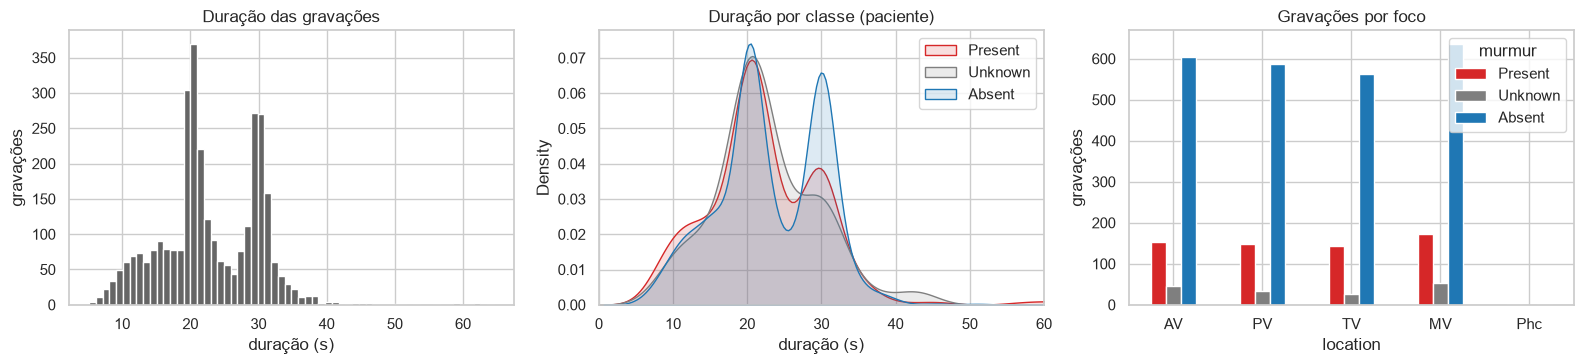

count    3163.0
mean       22.9
std         7.3
min         5.2
25%        19.1
50%        21.5
75%        29.4
max        64.5


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
rec.duration.hist(bins=60, ax=ax[0], color='0.4'); ax[0].set(xlabel='duração (s)', ylabel='gravações', title='Duração das gravações')
for c in CLASSES:
    sns.kdeplot(rec.loc[rec.murmur == c, 'duration'], ax=ax[1], color=PALETTE[c], label=c, fill=True, alpha=.15)
ax[1].set(xlabel='duração (s)', xlim=(0, 60), title='Duração por classe (paciente)'); ax[1].legend()
pd.crosstab(rec.location, rec.murmur).reindex(index=['AV', 'PV', 'TV', 'MV', 'Phc'], columns=CLASSES).dropna(how='all').plot.bar(
    ax=ax[2], color=[PALETTE[c] for c in CLASSES], rot=0)
ax[2].set(title='Gravações por foco', ylabel='gravações')
plt.tight_layout(); save('recordings_duration_location'); plt.show()
print(rec.duration.describe().round(1).to_string())

**Leitura.**
- Todas as gravações estão a **4 kHz** (Nyquist 2 kHz), por isso não reamostramos. No UrbanSound8K reamostrámos tudo para 22 kHz.
- A duração varia muito (≈5–65 s, mediana ≈21 s), muito acima dos 4 s fixos do UrbanSound8K. Cortar ou preencher cada gravação
  para um único tamanho deitaria fora a maior parte do sinal. Em vez disso **partimos cada gravação em janelas de 4 s**:
  dá uma entrada de tamanho fixo e multiplica o número de exemplos de treino (~10 janelas por gravação).
- A maioria dos pacientes tem os 4 focos (AV, PV, TV, MV). `Phc` é raro (4 ficheiros) e alguns focos estão repetidos (`_1`, `_2`).
- A duração não separa as classes, por isso não é atalho para o modelo.

## 5. Focos com sopro → rótulos por gravação
Num paciente *Present*, o sopro pode ouvir-se só nalguns focos. Se cada gravação herdar o rótulo do paciente,
treinamos com rótulos errados (gravações sem sopro marcadas *Present*).
O campo `Murmur locations` permite construir um **rótulo por gravação** (`rec_label`, em `src/data.py`):
*Present* se o foco está em `Murmur locations`, senão *Absent*. Os pacientes *Unknown*/*Absent* mantêm o rótulo.

In [10]:
n_rec = present['Recording locations:'].str.split('+').apply(lambda l: len(set(l)))
n_mur = present['Murmur locations'].str.split('+').apply(len)
display(pd.crosstab(n_rec.rename('focos gravados'), n_mur.rename('focos com sopro')))

ct = pd.crosstab(rec.murmur, rec.rec_label).reindex(index=CLASSES, columns=CLASSES)
display(ct)
p = rec[rec.murmur == 'Present']
print(f'{(p.rec_label == "Absent").mean():.0%} das gravações de pacientes Present não têm sopro audível no seu foco')

rate = p.groupby('location').rec_label.apply(lambda s: (s == 'Present').mean()).reindex(['AV', 'PV', 'TV', 'MV'])
print('\nP(sopro audível | foco, paciente Present):'); print(rate.round(2).to_string())

focos com sopro,1,2,3,4,5
focos gravados,,,,,
1,10,0,0,0,0
2,8,19,0,0,0
3,4,7,11,0,0
4,12,21,16,70,0
5,0,0,0,0,1


rec_label,Present,Unknown,Absent
murmur,,,
Present,499,0,117
Unknown,0,156,0
Absent,0,0,2391


19% das gravações de pacientes Present não têm sopro audível no seu foco

P(sopro audível | foco, paciente Present):
location
AV    0.72
PV    0.83
TV    0.88
MV    0.81


**Leitura.** Cerca de 1 em cada 5 gravações de pacientes *Present* não tem sopro naquele foco, o que seria ruído no rótulo.
Treinamos com `rec_label` e avaliamos sempre com o rótulo do **paciente**.
Isto também sugere a agregação por paciente: **basta um foco com sopro** para o paciente ser *Present*,
por isso o máximo de P(Present) entre gravações é mais natural do que a média (`aggregate_to_patient(..., how='max_present')`).
O sopro ouve-se mais vezes em TV e PV e menos vezes em AV. O foco pode ser uma entrada útil, mas não o usamos por agora.

## 6. Segmentações (.tsv): ciclo cardíaco, frequência cardíaca e energia na sístole
Cada gravação tem uma segmentação `start, end, state` (0 = não anotado, 1 = S1, 2 = sístole, 3 = S2, 4 = diástole).
**Não as usamos como entrada dos modelos**, porque os dados escondidos do bónus podem não as trazer.
Servem para perceber o sinal e confirmar que o sopro está onde esperamos.

In [11]:
seg_stats = pd.DataFrame([segmentation_stats(load_segmentation(r)) for r in tqdm(rec.recording, desc='tsv')], index=rec.index)
rec = rec.join(seg_stats)
rec['ann_frac'] = (rec.ann_end - rec.ann_start) / rec.duration
display(rec[['ann_frac', 'n_cycles', 'heart_rate', 'rr_cv', 'dur_S1', 'dur_systole', 'dur_S2', 'dur_diastole']].describe().round(2))

tsv: 100%|██████████| 3163/3163 [00:04<00:00, 664.36it/s]


,ann_frac,n_cycles,heart_rate,rr_cv,dur_S1,dur_systole,dur_S2,dur_diastole
count,3163.00,3163.00,3162.00,3162.00,3162.00,3162.00,3162.00,3162.00
mean,0.55,20.35,105.39,0.08,0.12,0.14,0.10,0.23
std,0.29,12.91,20.48,0.17,0.02,0.03,0.02,0.08
min,0.00,0.00,46.15,0.00,0.04,0.04,0.03,0.08
25%,0.29,11.00,90.91,0.04,0.11,0.12,0.09,0.17
50%,0.52,17.00,103.45,0.05,0.12,0.14,0.10,0.21
75%,0.84,27.00,118.92,0.07,0.13,0.16,0.12,0.28
max,1.00,94.00,197.95,5.31,0.20,0.47,0.18,0.78


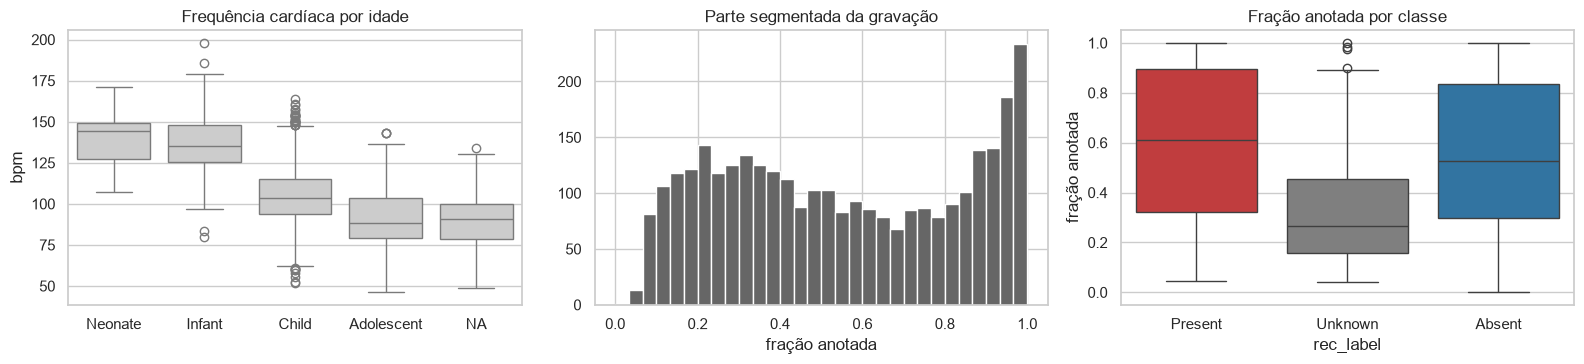

In [12]:
age = rec.patient_id.map(pat.Age).fillna('NA')
order = ['Neonate', 'Infant', 'Child', 'Adolescent', 'NA']
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(x=age, y=rec.heart_rate, order=[o for o in order if o in set(age)], ax=ax[0], color='0.8')
ax[0].set(xlabel='', ylabel='bpm', title='Frequência cardíaca por idade')
rec.ann_frac.hist(bins=30, ax=ax[1], color='0.4'); ax[1].set(xlabel='fração anotada', title='Parte segmentada da gravação')
sns.boxplot(x=rec.rec_label, y=rec.ann_frac, order=CLASSES, palette=PALETTE, ax=ax[2])
ax[2].set(xlabel='rec_label', ylabel='fração anotada', title='Fração anotada por classe')
plt.tight_layout(); save('segmentation_stats'); plt.show()

Agora a pergunta principal: **há mais energia na sístole quando há sopro?**
Para cada gravação calculamos a potência média do sinal filtrado (25–1000 Hz) em cada fase.
Normalizamos pela potência de S1, o que tira o efeito do volume de cada gravação.

100%|██████████| 3163/3163 [00:19<00:00, 163.28it/s]


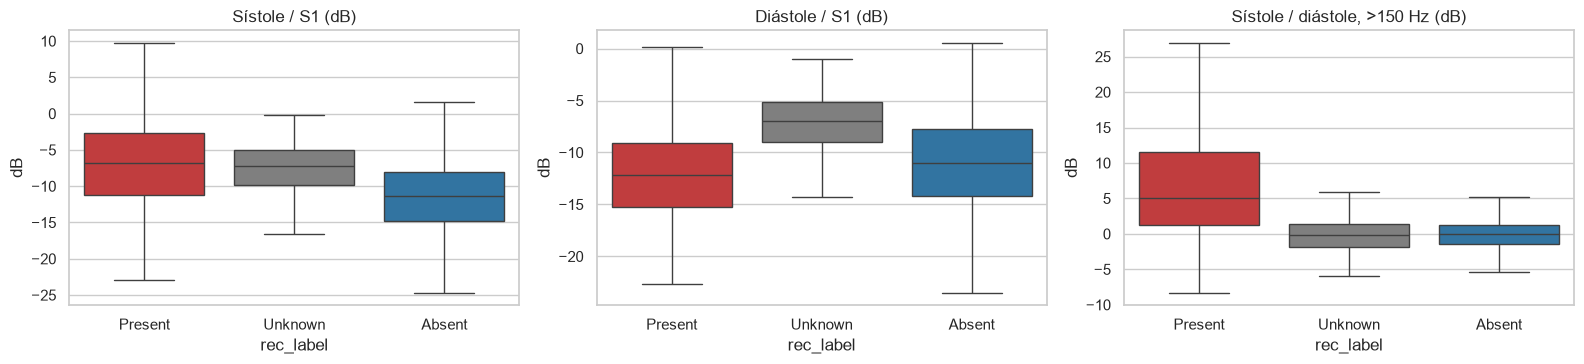

,sys_S1_db,dia_S1_db,sys_dia_hf_db
rec_label,,,
Present,-6.8,-12.2,5.1
Unknown,-7.3,-7.0,-0.1
Absent,-11.4,-11.0,0.0


In [13]:
def phase_power(path, seg, f_low=None):
    y = F.load_audio(path)
    if f_low:  # componente de alta frequência (sopros são mais agudos que S1/S2)
        y = ss.sosfiltfilt(ss.butter(4, f_low, 'highpass', fs=F.AUDIO.sr, output='sos'), y)
    sr, out = F.AUDIO.sr, {}
    for k, name in [(1, 'S1'), (2, 'systole'), (3, 'S2'), (4, 'diastole')]:
        s = seg[seg.state == k]
        seg_pow = [np.mean(y[int(a * sr):int(b * sr)] ** 2) for a, b in zip(s.start, s.end) if b - a > 0.01]
        out[name] = np.median(seg_pow) if seg_pow else np.nan
    return out

pp = pd.DataFrame([phase_power(p, load_segmentation(r)) for p, r in tqdm(zip(rec.path, rec.recording), total=len(rec))], index=rec.index)
pp_hf = pd.DataFrame([phase_power(p, load_segmentation(r), f_low=150) for p, r in tqdm(zip(rec.path, rec.recording), total=len(rec))], index=rec.index)
rec['sys_S1_db'] = 10 * np.log10(pp.systole / pp.S1)
rec['dia_S1_db'] = 10 * np.log10(pp.diastole / pp.S1)
rec['sys_dia_hf_db'] = 10 * np.log10(pp_hf.systole / pp_hf.diastole)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, t in zip(ax, ['sys_S1_db', 'dia_S1_db', 'sys_dia_hf_db'],
                     ['Sístole / S1 (dB)', 'Diástole / S1 (dB)', 'Sístole / diástole, >150 Hz (dB)']):
    sns.boxplot(x=rec.rec_label, y=rec[col], order=CLASSES, palette=PALETTE, ax=a, showfliers=False)
    a.set(xlabel='rec_label', ylabel='dB', title=t)
plt.tight_layout(); save('phase_energy_by_class'); plt.show()
display(rec.groupby('rec_label')[['sys_S1_db', 'dia_S1_db', 'sys_dia_hf_db']].median().reindex(CLASSES).round(1))

**Leitura.**
- A frequência cardíaca desce com a idade (mediana ≈ 103 bpm, mínimo 46 bpm). Uma janela de 4 s tem **~7 ciclos na mediana**
  e **pelo menos ~3** mesmo no batimento mais lento, o que confirma a escolha do tamanho da janela.
- As segmentações cobrem só parte de cada gravação: o anotador segmentou um troço limpo. O resto pode ter mais ruído.
- Nas gravações com sopro a **sístole tem muito mais energia relativa** (face a S1 e à diástole, sobretudo acima de 150 Hz),
  enquanto a diástole muda pouco. É exatamente o padrão descrito no §3, agora medido no sinal.
  Logo, uma representação tempo-frequência que mostre o que acontece *entre* S1 e S2 é o que a CNN precisa.
  Para a MLP, as estatísticas espectrais e de banda captam o mesmo de forma global.

## 7. Exemplos de sinais e conteúdo espectral

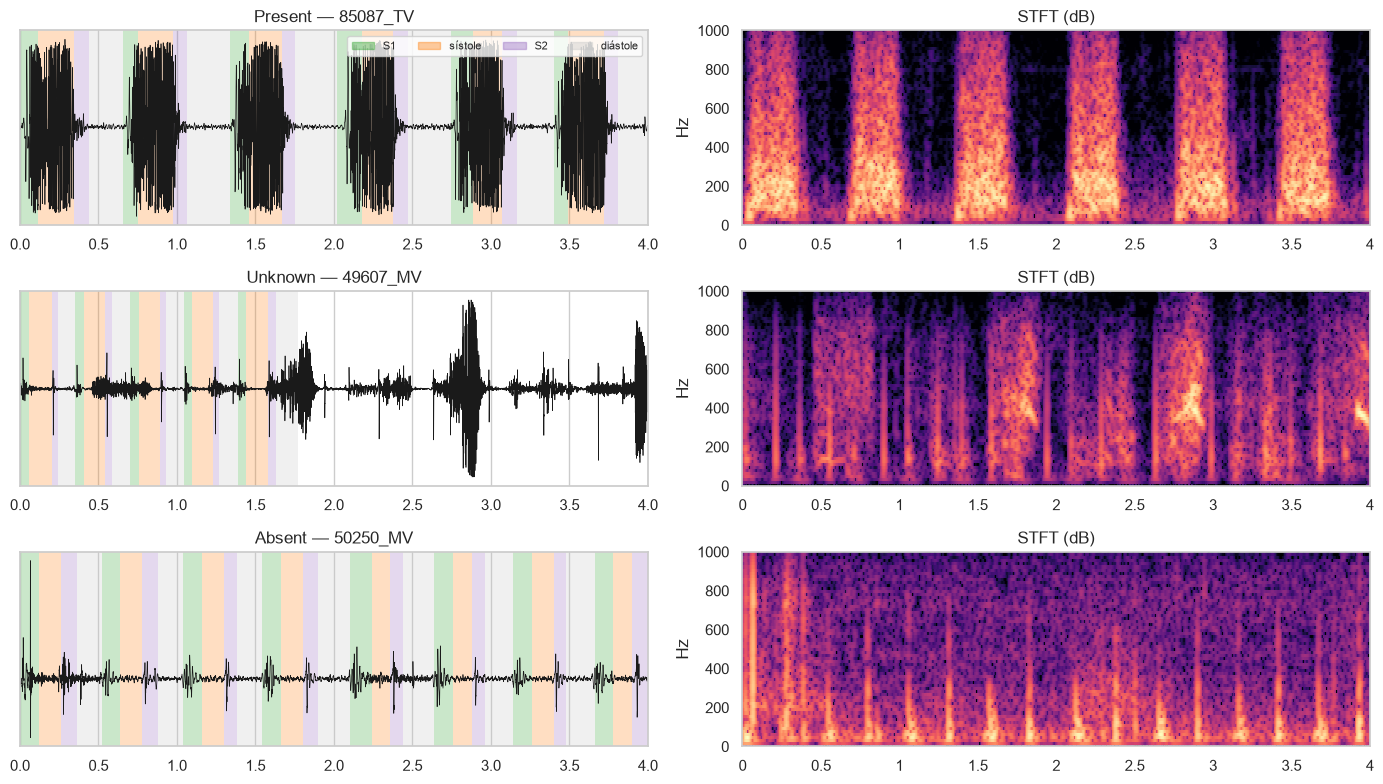

In [14]:
def show_example(r, ax_wave, ax_spec, seconds=4):
    y = F.load_audio(r.path); sr = F.AUDIO.sr
    seg = load_segmentation(r.recording)
    t0 = seg[seg.state == 1].start.min() if (seg.state == 1).any() else 0  # começar num S1 anotado
    y = y[int(t0 * sr):int((t0 + seconds) * sr)]
    t = np.arange(len(y)) / sr
    ax_wave.plot(t, y, lw=.5, color='k')
    colors = {1: '#2ca02c', 2: '#ff7f0e', 3: '#9467bd', 4: '#c7c7c7'}
    for a, b, s in seg[(seg.end > t0) & (seg.start < t0 + seconds)].itertuples(index=False):
        if s in colors: ax_wave.axvspan(max(a - t0, 0), min(b - t0, seconds), color=colors[s], alpha=.25, lw=0)
    ax_wave.set(xlim=(0, seconds), title=f'{r.rec_label} — {r.recording}', yticks=[])
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=256, hop_length=16)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=16, x_axis='time', y_axis='linear', ax=ax_spec, cmap='magma', vmin=-70)
    ax_spec.set(ylim=(0, 1000), xlabel='', title='STFT (dB)')

# exemplos ilustrativos: o Present com mais energia sistólica (>150 Hz), o Unknown com menor
# parte segmentada (o anotador só conseguiu segmentar um troço) e um Absent mediano
ok = rec[rec.n_cycles.gt(3)]
ex = [ok[ok.rec_label == 'Present'].sort_values('sys_dia_hf_db').iloc[-1],
      ok[ok.rec_label == 'Unknown'].sort_values('ann_frac').iloc[0],
      ok[ok.rec_label == 'Absent'].sort_values('sys_dia_hf_db').iloc[len(ok[ok.rec_label == 'Absent']) // 2]]
fig, axes = plt.subplots(3, 2, figsize=(14, 8))
for r, (a1, a2) in zip(ex, axes): show_example(r, a1, a2)
from matplotlib.patches import Patch
axes[0, 0].legend(handles=[Patch(color=c, alpha=.4, label=l) for c, l in
                           zip(['#2ca02c', '#ff7f0e', '#9467bd', '#c7c7c7'], ['S1', 'sístole', 'S2', 'diástole'])],
                  ncol=4, loc='upper right', fontsize=8)
plt.tight_layout(); save('example_signals'); plt.show()

Para cada gravação calculamos o espectro médio (Welch, sinal normalizado) e vemos a média por classe:

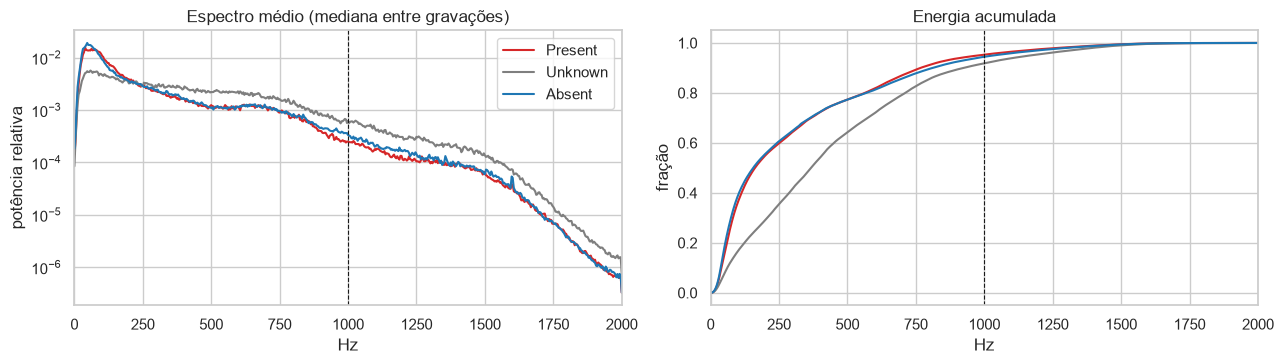

Present  50%/90%/99% da energia abaixo de [164, 769, 1414] Hz
Unknown  50%/90%/99% da energia abaixo de [367, 925, 1496] Hz
Absent   50%/90%/99% da energia abaixo de [156, 812, 1433] Hz


In [15]:
specs = {}
for c in CLASSES:
    paths = rec[rec.rec_label == c].path
    paths = paths.sample(min(len(paths), 150), random_state=0)  # amostra para ser rápido
    ps = []
    for p in paths:
        y, sr = librosa.load(p, sr=None)
        f, pxx = ss.welch((y - y.mean()) / (y.std() + 1e-8), fs=sr, nperseg=1024)
        ps.append(pxx / pxx.sum())
    specs[c] = np.array(ps)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for c in CLASSES:
    m = np.median(specs[c], 0)
    ax[0].semilogy(f, m, color=PALETTE[c], label=c)
    ax[1].plot(f, np.cumsum(specs[c].mean(0)), color=PALETTE[c], label=c)
for a in ax: a.axvline(1000, ls='--', color='k', lw=.8); a.set(xlabel='Hz', xlim=(0, 2000))
ax[0].set(title='Espectro médio (mediana entre gravações)', ylabel='potência relativa'); ax[0].legend()
ax[1].set(title='Energia acumulada', ylabel='fração');
plt.tight_layout(); save('spectrum_by_class'); plt.show()
for c in CLASSES:
    cum = np.cumsum(specs[c].mean(0))
    print(f'{c:8s} 50%/90%/99% da energia abaixo de', [int(f[np.searchsorted(cum, q)]) for q in (.5, .9, .99)], 'Hz')

Nos exemplos: no *Present* vê-se energia contínua entre S1 e S2 (faixa laranja), ausente no *Absent*.
No *Unknown* há ruído forte e irregular que esconde o ciclo (e só parte da gravação foi segmentada).

**Leitura.**
- S1 e S2 concentram-se abaixo de ~150 Hz. Os sopros espalham energia pela sístole até algumas centenas de Hz.
  Acima de ~1 kHz há sobretudo ruído (fricção, fala, choro).
- Daí o **filtro passa-banda 25–1000 Hz**: abaixo de 25 Hz há deriva e movimento, acima de 1 kHz há pouco sinal útil.
  Pela mesma razão o mel-espectrograma vai só até 1000 Hz: concentra as bandas mel onde está a informação.
- As gravações *Unknown* têm o espectro deslocado para frequências mais altas, compatível com mais ruído.

## 8. Qualidade do sinal: o que distingue *Unknown*?
*Unknown* significa que o médico não conseguiu decidir, muitas vezes por ruído. Duas medidas simples por gravação:
- **periodicidade**: pico da autocorrelação do envelope de energia entre 0.3 e 1.5 s (40–200 bpm).
  Num som cardíaco limpo é alto; com ruído é baixo.
- **picos/artefactos**: fração de amostras com |z| > 6 (pancadas no estetoscópio, cliques).

qualidade: 100%|██████████| 3163/3163 [00:27<00:00, 114.47it/s]


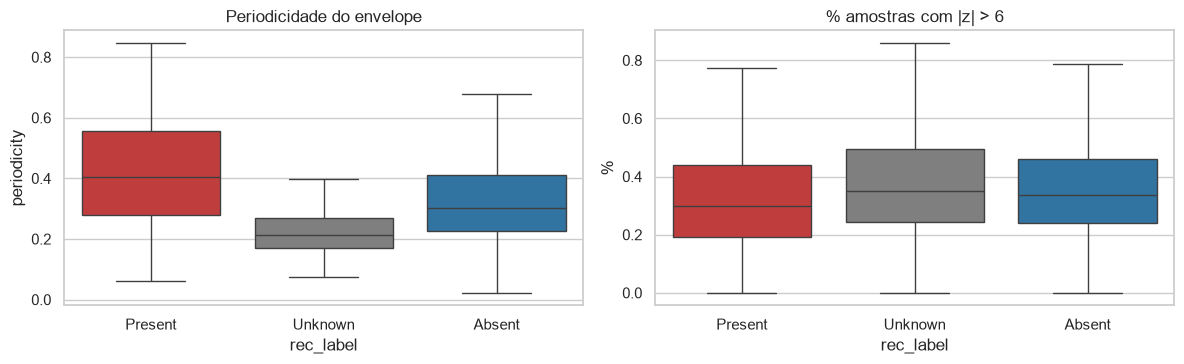

,periodicity,spikes
rec_label,,
Present,0.405,0.003
Unknown,0.212,0.004
Absent,0.301,0.003


In [16]:
def quality(path):
    y = F.load_audio(path)
    w = y[:F.AUDIO.window_len * 5]  # primeiros 20 s
    per = np.median([F.envelope_periodicity(x)[0] for x in F.split_windows(w)[0]])
    return {'periodicity': per, 'spikes': np.mean(np.abs(y) > 6)}

q = pd.DataFrame([quality(p) for p in tqdm(rec.path, desc='qualidade')], index=rec.index)
rec = rec.join(q)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(x=rec.rec_label, y=rec.periodicity, order=CLASSES, palette=PALETTE, ax=ax[0], showfliers=False)
ax[0].set(title='Periodicidade do envelope', xlabel='rec_label')
sns.boxplot(x=rec.rec_label, y=100 * rec.spikes, order=CLASSES, palette=PALETTE, ax=ax[1], showfliers=False)
ax[1].set(title='% amostras com |z| > 6', xlabel='rec_label', ylabel='%')
plt.tight_layout(); save('signal_quality'); plt.show()
display(rec.groupby('rec_label')[['periodicity', 'spikes']].median().reindex(CLASSES).round(3))

**Leitura.** As gravações *Unknown* são menos periódicas, ou seja, o ciclo cardíaco percebe-se pior.
Por isso incluímos a periodicidade do envelope nas features da MLP. Na CNN a mesma informação está implícita
no espectrograma: a regularidade de S1/S2 ao longo do tempo. Mesmo assim, *Unknown* vai ser a classe mais difícil
(é a mais pequena e é definida por "ninguém conseguiu decidir").

Não descartamos gravações ruidosas: o conjunto escondido também as terá e o modelo tem de saber responder *Unknown*.

## 9. Conclusões para o pré-processamento
O que a exploração decide (implementado em `src/features.py` e `src/prepare_data.py`, demonstrado em `02_preprocessing.ipynb`):

| observação (secção) | decisão |
|---|---|
| WA penaliza falhar *Present*; *Absent* domina (§1) | pesos de classe na loss e limiar afinado na validação |
| a mesma criança nas duas campanhas, rótulos às vezes diferentes (§2) | split por grupo (já no `split.csv`); aceitar um teto de *accuracy* |
| sopros sistólicos, fracos, entre S1 e S2 (§3, §6) | janelas com ciclos completos e resolução temporal de ~10 ms |
| tudo a 4 kHz, 5–65 s, ~4 focos por paciente (§4) | sem reamostragem; **janelas de 4 s** (passo 2 s) em vez de crop/pad |
| ~1 em 5 gravações *Present* sem sopro no foco (§5) | treinar com **`rec_label`**; agregar por paciente com o máximo de P(Present) |
| frequência cardíaca entre 46 e ~170 bpm, mediana 103 (§6) | 4 s chegam para ≥ 3 ciclos (~7 na mediana) |
| energia útil < 1 kHz, ruído acima (§7) | **passa-banda 25–1000 Hz**; mel até 1000 Hz |
| *Unknown* = ruidoso, pouco periódico (§8) | feature de periodicidade na MLP; nível absoluto em dB na CNN (sem min-max) |
| segmentações só cobrem parte e podem faltar nos dados escondidos (§6) | **não usar .tsv como entrada** |